# Using the shared anomaly detection module

This notebook demonstrates how to use `detection.py` to turn telemetry
forecasts into anomaly alerts

For the detailed explanation of the procedure see `Rios_Telemon_P1_Reproduction.ipynb`

The authors’ LSTM forecasts sensor values. The detection module compares predictions with actual readings, smooths the prediction errors, selects thresholds, identifies and buffers candidate anomalies, prunes candidates, and merges retained detections into intervals.

The module does not train models or generate predictions. It takes existing predictions as input, allowing us to apply the same detection procedure to different forecasting models and channels. Comparing the resulting alerts with labeled events is a separate evaluation step.

## Example workflow

Procedure is demonstrated using the authors’ saved P-1 predictions, for which the module has been verified against our reproduction notebook.

To use another channel, change the channel name and supply the appropriate settings. Comments in the code explain where to find those settings. The same loading, detection, and plotting cells can then be reused.

## Required inputs

- The channel’s full test telemetry.
- One scalar prediction per forecasted time step, in the same scaling as
  the actual telemetry.
- The prediction alignment and detection settings for that channel.

The first prediction must correspond to test-data index `history_length`, and subsequent predictions must correspond to consecutive readings. The `n_predictions` setting specifies how many actual future targets are used for the telemetry-scale checks; the test data must contain those targets.

In [1]:
from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt

# Locate the repository root
# This supports running from the root or one folder below it,
# such as EDA_Results or Models.
repo_dir = Path.cwd().resolve()

if not (repo_dir / "detection.py").is_file():
    repo_dir = repo_dir.parent

if not (repo_dir / "detection.py").is_file():
    raise FileNotFoundError(
        "Could not find detection.py. Run this notebook from "
        "the repository root or EDA_Results folder."
    )

# Allow this notebook to import the shared module.
if str(repo_dir) not in sys.path:
    sys.path.insert(0, str(repo_dir))

import detection

# These paths assume the dataset is stored locally under data/data
# If you store it elsewhere, change data_dir to that location
data_dir = repo_dir / "data" / "data"

# Select the saved run containing the predictions you want to evaluate.
# In this dataset, runs are stored in timestamped folders.
# Each run's params.log records its settings.
# Change this path when using predictions from a different run.
run_dir = data_dir / "2018-05-19_15.00.10"

## Example 1: P-1 with the authors’ saved predictions

The following loads P-1’s test telemetry and the authors’ saved LSTM predictions.

The test array contains the target sensor in column 0 and additional features in the remaining columns. The predictions will be passed to the detection module alongside the full test array.


In [2]:
# Change this name to use another channel, such as "D-14".
channel = "P-1"

test_data = np.load(data_dir / "test" / f"{channel}.npy")
predictions = np.load(run_dir / "y_hat" / f"{channel}.npy")

In [3]:
# Settings below match the authors' 2018-05-19_15.00.10 run.
# For a different run, consult its params.log:
# history_length is recorded as l_s; the other run parameters
# use the same names shown below.


# Two rules come from the authors' errors.py rather than params.log:
# - initial_adjustment: False for C-2; True for other channels

# - initial_ignore value depends on len(predictions):
#     fewer than 1800: set this value = 0
#     1800–2499:  set this value =  history_length
#     2500 or more:  set this value =  2 * history_length

# Example: P-1 has 8245 predictions and history_length = 250,
# that means initial_ignore = 2 * 250 = 500
# target_column=0 selects the target sensor in this dataset.

results = detection.detect_anomalies(
    test_data=test_data,
    predictions=predictions,
    history_length=250,
    n_predictions=10,
    target_column=0,
    batch_size=70,
    window_size=30,
    smoothing_perc=0.05,
    error_buffer=100,
    p=0.13,
    initial_adjustment=True,  # Change to False for C-2.
    initial_ignore=500       # Update using the prediction count rule above.
)

print(f"Detected anomaly intervals for {channel}: {results['detected_intervals']}")

Detected anomaly intervals for P-1: [(2130, 2349), (3190, 3329), (3540, 3679), (4520, 4589)]


## The following interpretation applies specifically to P-1 with the saved run and settings used above. If you change the channel, compare its detected intervals with its own labels in `labeled_anomalies.csv` and update the interpretation accordingly.


###### Interpreting the P-1 results

Using the authors’ saved predictions, the module produces four anomalyalerts, expressed as inclusive intervals in the original test-data indices:

| Detected interval | Comparison with the labeled events |
|---|---|
| 2130–2349 | Overlaps the labeled event at 2149–2349 |
| 3190–3329 | Does not overlap a labeled event: a false alert |
| 3540–3679 | Overlaps the labeled event at 3539–3779 |
| 4520–4589 | Overlaps the labeled event at 4536–4844 |

Under an event-overlap evaluation—where any overlap counts as detecting a labeled event—these results give **3 true positives, 1 false positive, and 0 false negatives**. This corresponds to an event precision of **75%** and event recall of **100%**.

Detecting an event does not mean identifying its entire duration. For example, the final alert overlaps only part of the labeled event at 4536–4844. These event-level results therefore do not measure how accurately the alert boundaries match the labels.

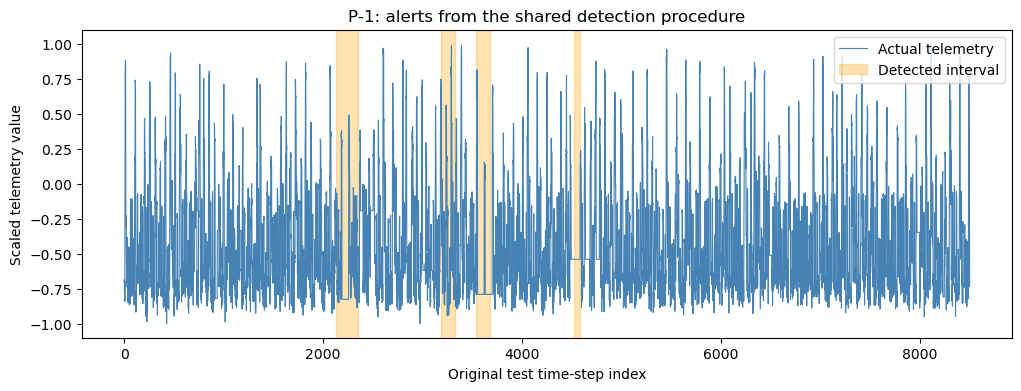

In [4]:
# Plot the selected channel's target sensor (column 0 in this dataset).
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    np.arange(len(test_data)),
    test_data[:, 0],
    color="steelblue",
    linewidth=0.8,
    label="Actual telemetry"
)

# Shade each interval detected by the module.
## IMPORTANT INFORMATION
# These are alerts, not the dataset's labeled anomaly intervals.
for i, (start, end) in enumerate(results["detected_intervals"]):
    ax.axvspan(
        start,
        end,
        color="orange",
        alpha=0.3,
        label="Detected interval" if i == 0 else None
    )

# The title updates automatically when the channel changes.
ax.set(
    title=f"{channel}: alerts from the shared detection procedure",
    xlabel="Original test time-step index",
    ylabel="Scaled telemetry value"
)
ax.legend()
plt.show()

## Evaluate the detected alerts

This cell loads the selected channel’s labeled anomaly events and calls
`detection.evaluate_event_detection` to compare them with the detected alerts.

It reports true positives, false positives, missed events, precision, recall, and F1. Any overlap counts as detecting an event.

No changes are needed here when switching channels; rerun the loading
and detection cells first.

In [5]:
import ast
import pandas as pd

# Load the anomaly labels supplied with the dataset.
# Change this path if your label file is stored elsewhere.
labels = pd.read_csv(data_dir / "labeled_anomalies.csv")

# Select labels for the channel chosen in the loading cell.
# No change is needed here when switching channels.
channel_rows = labels.loc[labels["chan_id"] == channel]

if channel_rows.empty:
    raise ValueError(f"No anomaly labels found for channel {channel}.")

# The CSV stores anomaly intervals as text, such as "[[2149, 2349]]".
# Convert them into (start, end) pairs in original test-data indices.
# Some channels have multiple rows, so combine their labeled events
# and remove exact duplicates.
labeled_intervals = sorted({
    (int(start), int(end))
    for sequences in channel_rows["anomaly_sequences"]
    for start, end in ast.literal_eval(sequences)
})

# Evaluate the alerts generated by the detection cell above.
# A labeled event is detected if at least one alert overlaps it.
# A false alert overlaps no labeled event.
# These metrics measure event detection, not alert-boundary accuracy.
evaluation = detection.evaluate_event_detection(
    detected_intervals=results["detected_intervals"],
    labeled_intervals=labeled_intervals
)

# Display results for the selected channel automatically.
# Precision: TP / (TP + FP).
# Recall: TP / (TP + FN).
# F1 combines precision and recall.
# An undefined metric is displayed as nan.
print(f"Event-overlap evaluation for {channel}")
print(f"Labeled events: {labeled_intervals}")
print(
    f"TP: {evaluation['TP']}, "
    f"FP: {evaluation['FP']}, "
    f"FN: {evaluation['FN']}"
)
print(f"Precision: {evaluation['precision']:.1%}")
print(f"Recall: {evaluation['recall']:.1%}")
print(f"F1: {evaluation['f1']:.3f}")

Event-overlap evaluation for P-1
Labeled events: [(2149, 2349), (3539, 3779), (4536, 4844)]
TP: 3, FP: 1, FN: 0
Precision: 75.0%
Recall: 100.0%
F1: 0.857


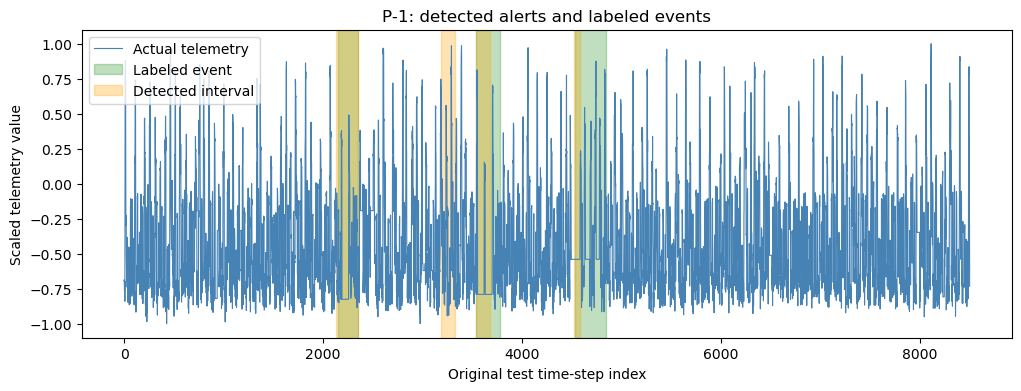

In [7]:
# Plot the selected channel's target sensor.
# If you change target_column in detection, use that column here too.
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    np.arange(len(test_data)),
    test_data[:, 0],
    color="steelblue",
    linewidth=0.8,
    label="Actual telemetry"
)

# Green regions show the labeled events loaded in the evaluation cell.
for i, (start, end) in enumerate(labeled_intervals):
    ax.axvspan(
        start, end,
        color="green",
        alpha=0.25,
        label="Labeled event" if i == 0 else None
    )

# Orange regions show the alerts produced by detection.py.
# Overlapping shaded regions indicate detected portions of labeled events.
for i, (start, end) in enumerate(results["detected_intervals"]):
    ax.axvspan(
        start, end,
        color="orange",
        alpha=0.3,
        label="Detected interval" if i == 0 else None
    )

# The data, intervals, and title update when you rerun for another channel.
ax.set(
    title=f"{channel}: detected alerts and labeled events",
    xlabel="Original test time-step index",
    ylabel="Scaled telemetry value"
)

ax.legend()
plt.show()

### Once again in case you didn't see the reproduction notebook, why do these P-1 results differ from the authors’ saved report?

The authors’ saved report gives **2 true positives, 1 false positive, and 1 missed event**. Our corrected indexing implementation gives **3 true positives, 1 false positive, and no missed events**.

The difference comes from an indexing error in the historical pruning calculation. Pruning compares candidate peaks with the largest error outside current candidates and previously retained anomalies. To do this correctly, positions within the current window and previous detections must be compared in the same coordinate system.

The historical code introduced a one batch offset—70 readings for this run when accounting for previous detections. This changed the outside error used in pruning and removed the alert overlapping P-1’s middle labeled event.

That historical offset was recreated and recovered the saved report’s counts. The LSTM predictions and smoothed errors stayed the same. Only the pruning comparison changed.

The shared module uses corrected indexing going forward. Its additional P-1 detection reflects that correction, not a newly trained or improved forecasting model.